In [138]:
import osmnx as ox
import geopandas as gpd
import neatnet
import momepy
import matplotlib.pyplot as plt

In [139]:
gdf = gpd.read_file("../data/raw/rome_sample.gpkg")

In [140]:
G = ox.graph_from_polygon(gdf.geometry[0], network_type="drive")
G = ox.project_graph(G)
streets = ox.graph_to_gdfs(
    ox.convert.to_undirected(G),
    nodes=False,
    edges=True,
    node_geometry=False,
    fill_edge_geometry=True,
).reset_index(drop=True)

In [141]:
len(ox.convert.to_undirected(G).edges)

500

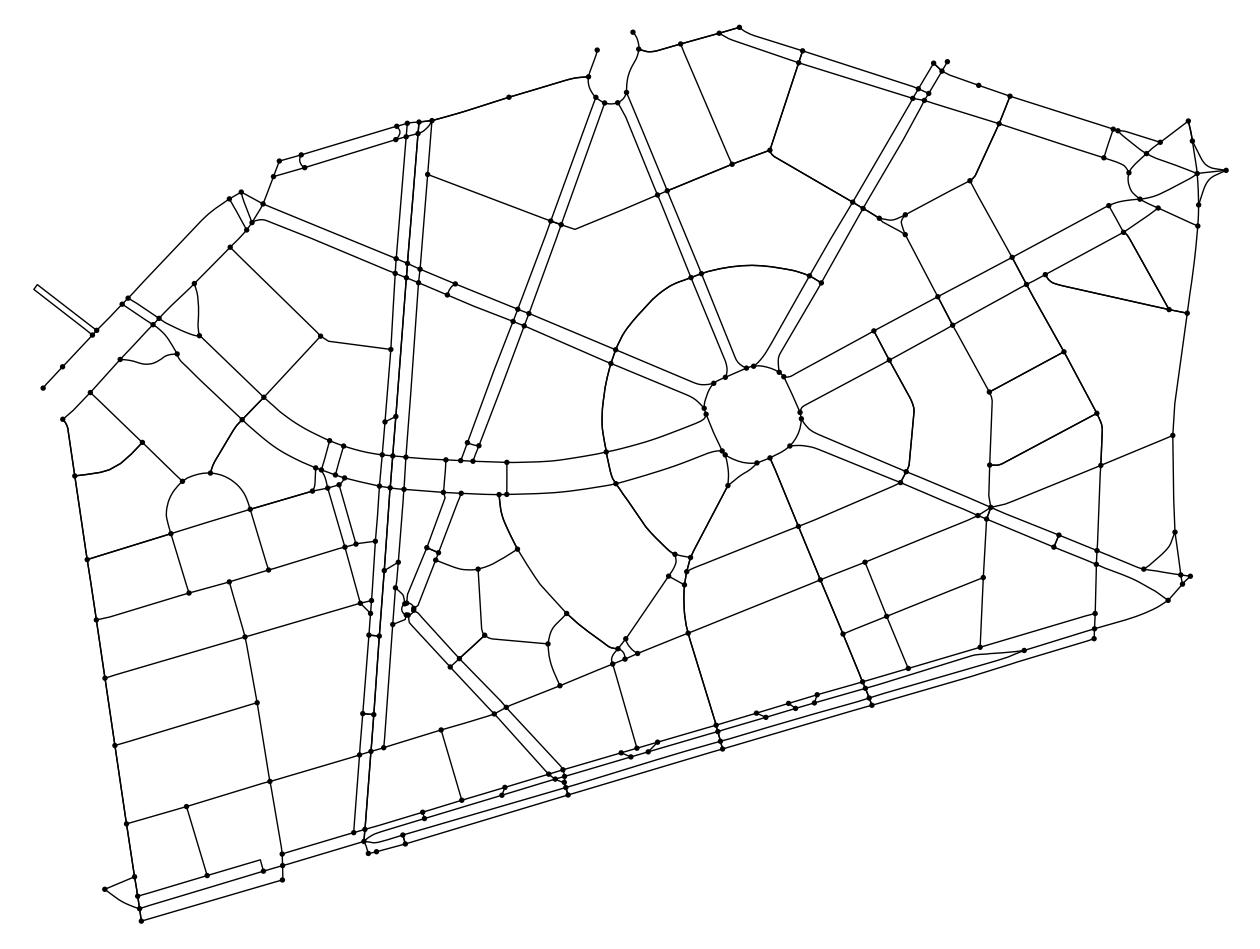

(<Figure size 1600x1600 with 1 Axes>, <Axes: >)

In [142]:
ox.plot_graph(
    G, bgcolor="white", node_color="black", edge_color="black", figsize=(16, 16)
)

In [143]:
buildings = (
    ox.features_from_polygon(gdf.geometry[0], tags={"building": True})
    .query('building != "roof"')
    .to_crs(streets.crs)
)

In [144]:
simplified = neatnet.neatify(streets, exclusion_mask=buildings.geometry)

In [145]:
graph = momepy.gdf_to_nx(simplified, approach="primal")
len(graph)

144

In [146]:
while any([val == 1 for val in dict(graph.degree()).values()]):
    remove_list = [node for node, degree in dict(graph.degree()).items() if degree == 1]
    graph.remove_nodes_from(remove_list)
    gdf = momepy.nx_to_gdf(graph, points=False, lines=True)
    gdf = neatnet.remove_interstitial_nodes(gdf)
    graph = momepy.gdf_to_nx(gdf, approach="primal")
    print(len(graph), len(graph.edges))

136 224
134 222


In [147]:
gdf = momepy.nx_to_gdf(graph, points=True, lines=True)

<Axes: >

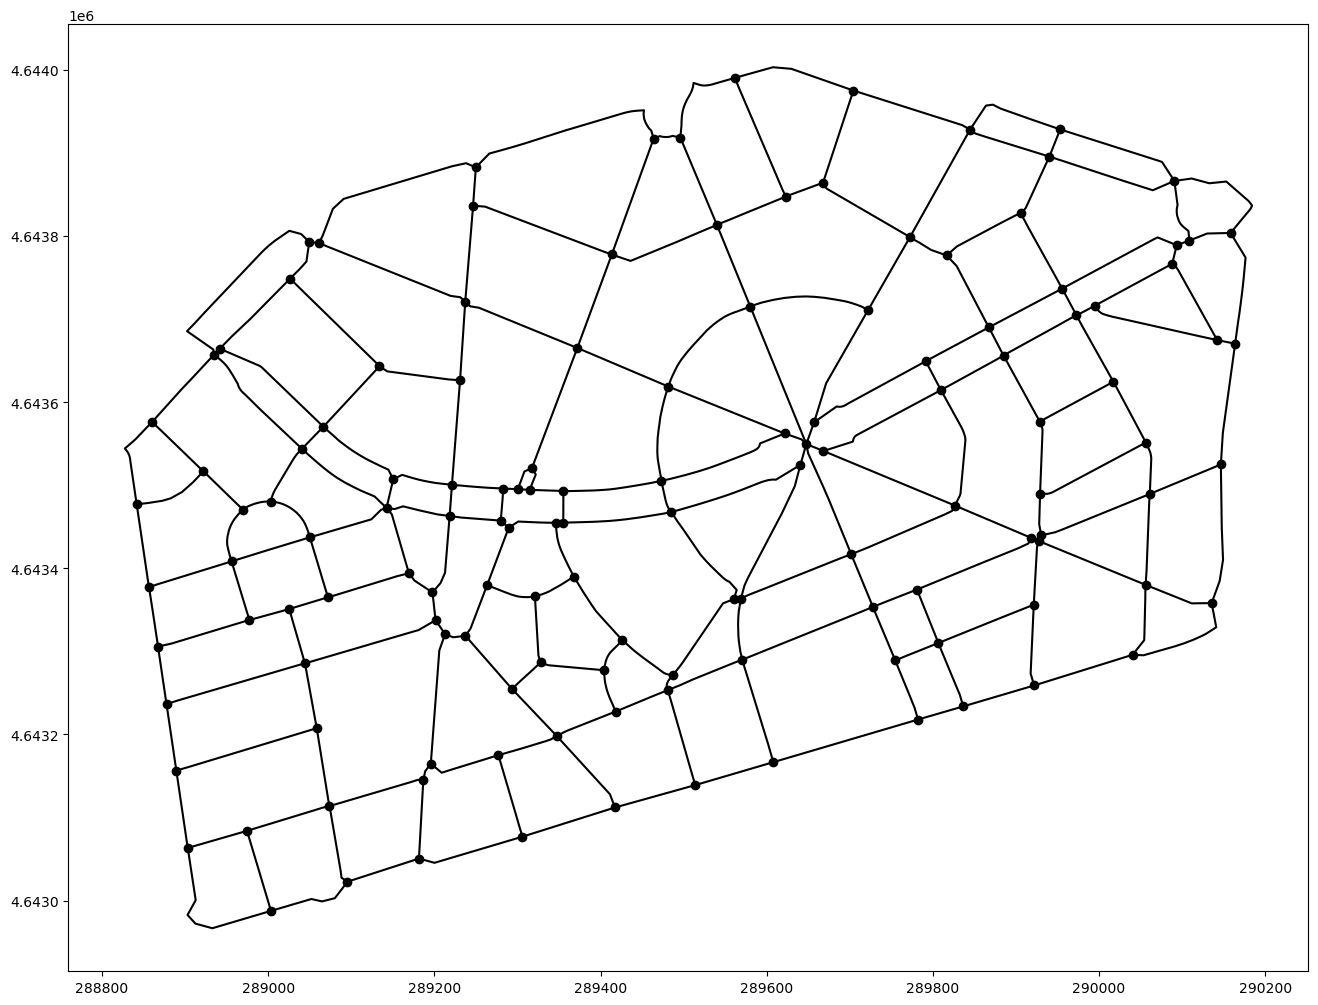

In [148]:
fig, ax = plt.subplots(figsize=(16, 16))
gdf[0].plot(ax=ax, color="black")
gdf[1].plot(ax=ax, color="black")

In [149]:
graph

In [150]:
gdf[1]

,geometry,_status,osmid,highway,lanes,maxspeed,name,oneway,reversed,length,from,to,junction,access,mm_len,node_start,node_end
0,"LINESTRING (288934.724 4643656.687, 288933.915...",changed,"[121403194, 1286438043, 120512037, 1286438042]",primary,"[2, 3]",50,Piazzale Clodio,True,False,168.837737,2.242582e+08,305335107.0,None,None,246.468211,0,1
1,"LINESTRING (288934.724 4643656.687, 288938.837...",changed,121897335,secondary,2,50,Viale Giuseppe Mazzini,True,False,110.318042,2.242582e+08,224335429.0,None,None,156.140947,0,28
2,"LINESTRING (288860.228 4643576.047, 288895.679...",changed,121898319,primary,3,50,Piazzale Clodio,True,False,52.929299,1.307339e+08,224258200.0,None,None,109.794831,0,29
3,"LINESTRING (288934.724 4643656.687, 288941.895...",original,60417829,primary,3,50,Piazzale Clodio,True,False,10.385454,3.053352e+08,724433131.0,None,None,10.392700,0,30
4,"LINESTRING (289026.424 4643748.753, 289037.123...",changed,121897313,primary,3,50,Piazzale Clodio,True,False,28.371122,2.243793e+08,224269843.0,None,None,52.142610,1,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,"LINESTRING (290088.002 4643766.433, 290093.427...",new,None,None,None,None,None,None,None,NaN,NaN,NaN,None,None,23.108938,128,129
218,"LINESTRING (290088.002 4643766.433, 290090.4 4...",original,33279194,residential,2,50,Via Don Giovanni Verità,False,True,107.052773,3.780810e+08,378080941.0,None,None,107.063069,129,131
219,"LINESTRING (289995.079 4643716.199, 290082.487...",original,130248371,residential,2,50,Viale Giuseppe Mazzini,True,False,105.440011,2.244906e+08,378080953.0,None,None,105.631880,129,130
220,"LINESTRING (290142.15 4643674.647, 290120.46 4...",original,20894092,residential,2,50,Via Giuseppe Montanelli,False,True,154.874292,3.780809e+08,224490557.0,None,None,155.255361,130,131


In [151]:
gdf[1].to_file(
    "../data/processed/ignored_files/paper/smurbnet/rome_simplified_edges.gpkg"
)